# Evidencias E1–E5 · Asistente RAG para datasheets de mecatrónica

**Inteligencia Artificial (18314) · UMNG · 2026-2 · Teoría A** · Estrategia: **GPT personalizado / RAG**
**Autor:** Esteban Felipe Monroy Contreras · **Equipo:** _(completar integrantes)_

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/EfMC/rag-datasheets-mecatronica/blob/main/notebooks/Evidencias_E1_E5.ipynb)

Respuesta breve a cada evidencia del instrumento. Las cifras se recalculan desde `reportes/`
(público); el detalle está en el [notebook completo](https://colab.research.google.com/github/EfMC/rag-datasheets-mecatronica/blob/main/notebooks/Proyecto_RAG_datasheets.ipynb)
y en `ANTECEDENTES.md`, `DECISIONES.md` (D1–D25) y `RESULTADOS.md` del
[repositorio](https://github.com/EfMC/rag-datasheets-mecatronica).

**Resultado principal:** corrección **0,83** (IC 95 % [0,75; 0,92]) frente a **0,58** sin RAG
(+0,26; p = 0,003); alucinación del **21 % → 2 %**.

In [1]:
# Configuración: en Colab clona el repositorio. Solo necesita pandas y matplotlib.
import os, sys, subprocess
from pathlib import Path
if "google.colab" in sys.modules:
    raiz = Path("/content/rag-datasheets-mecatronica")
    if not raiz.exists():
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/EfMC/rag-datasheets-mecatronica.git", str(raiz)], check=True)
else:
    raiz = Path.cwd() if (Path.cwd() / "reportes").exists() else Path.cwd().parent
os.chdir(raiz)
import math, random, warnings
import pandas as pd, matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 10.5, "font.size": 9})
GRIS, ACENTO = "#9aa0a6", "#1a73e8"
print("Repositorio listo en", raiz)

Repositorio listo en /home/claude/rag-datasheets-mecatronica


## E1 · Problema, antecedentes y justificación

**Problema.** Los datos técnicos de los componentes (límites de tensión y corriente, pines,
tiempos, tablas de calibración) están en datasheets de decenas a cientos de páginas, casi
siempre en inglés y muchas veces dentro de tablas. Ubicar un dato es lento, y leerlo mal
puede dañar el hardware.

**Necesidad de ingeniería.** Un asistente que responda en español sobre 23 documentos
(959 páginas, 6 familias, 8 fabricantes) y que cumpla tres condiciones:
1. Cite documento y página de cada dato, para poder verificarlo.
2. Se abstenga explícitamente cuando el dato no está, en lugar de inventarlo.
3. Funcione con recursos reales: PC sin GPU con 8 GB de RAM, presupuesto cero y una base que crece.

**Búsqueda sistemática** (protocolo completo en `ANTECEDENTES.md`):
- **Cinco preguntas de búsqueda:** RAG y alucinación; RAG en documentos técnicos y tablas;
  recuperación multilingüe y reordenamiento; tamaño de fragmento y contexto; evaluación y LLM
  como juez.
- **Fuentes:** arXiv, ACM SIGIR, NeurIPS y MDPI.
- **Criterios de inclusión:** trabajos de 2009 a 2026 verificados en su fuente original. Se
  incluyeron **14**.
- **Momento:** la búsqueda se hizo al final, para contrastar las decisiones, que se tomaron midiendo.

| Trabajo | Hallazgo | Relación con el proyecto |
|---|---|---|
| Lewis et al. (2020) | Proponen RAG: un generador condicionado a pasajes recuperados, con respuestas más factuales | Arquitectura base |
| Curavale et al. (2026), con Infineon | RAG sobre datasheets de microcontroladores con reordenador cross-encoder; BM25 es débil | Antecedente más cercano; mismas conclusiones |
| Lee y Choi (2026), TechDocRAG | Al fragmentar se pierden las relaciones de las tablas | Explica el principal error → mejora D22 |
| Soman y Roychowdhury (2024) | Los embeddings fallan con fragmentos largos | Respalda los fragmentos de 150 palabras |
| Bonifacio et al. (2021), mMARCO | Los reordenadores multilingües superan a los entrenados solo en inglés | Origen del reordenador usado |
| Zheng et al. (2023) | Un LLM juez coincide con humanos en más del 80 %, pero tiene sesgos | Juez auditado a mano |

**Brecha:** los antecedentes están en inglés y usan GPU. Este proyecto responde en español,
en CPU y con modelos gratuitos, y mide con pruebas pareadas cuánto aporta cada componente.

**Limitaciones de la programación clásica:**

| Enfoque clásico | Limitación | Evidencia medida |
|---|---|---|
| Palabras clave (Ctrl+F, BM25) | No relaciona español con inglés ni sinónimos | Encuentra la página en el 28 % de las preguntas, frente al 82 % del sistema |
| Reglas de extracción a una base de datos | Un formato distinto por fabricante; reglas por documento | 23 documentos, 8 fabricantes |
| LLM sin documentos | Inventa valores con seguridad | 21 % de alucinación |
| Ajuste fino (fine-tuning) | Requiere GPU y reentrenar con cada documento; no da citas | Sin GPU; la base crece |

**Justificación matemática.**

El modelo responde condicionado a los $k = 5$ fragmentos más relevantes, no de memoria:

$$p(y \mid x) \approx p_\theta\big(y \mid x, Z_k(x)\big)$$

La búsqueda semántica compara vectores de 384 dimensiones. Los textos equivalentes quedan
cerca aunque estén en otro idioma:

$$s(x,z) = \cos\big(E(\text{query: }x),\, E(\text{passage: }z)\big)$$

El reordenador (cross-encoder) lee la pregunta y cada fragmento juntos, y solo se aplica a
los 30 mejores candidatos:

$$s_{CE}(x,z) = \sigma\big(\mathbf{w}^\top h_{[x;z]}\big)$$

La temperatura 0 hace que las respuestas sean reproducibles.

## E2 · Datos, representación, estrategia y restricciones

**Origen y calidad:**
- Documentos oficiales de Espressif, STMicroelectronics, Siemens, Texas Instruments,
  Infineon, Vishay, Sharp y Tower Pro, más tablas de termocuplas IEC.
- Se reemplazaron los PDF escaneados (sin texto) por versiones oficiales.
- Se descartó un archivo mal etiquetado: el "2N7000" era en realidad el 2N7002.
- Un manifiesto define qué páginas indexar y excluye índices, pedidos, planos de empaque y
  avisos legales (D1–D2).

In [2]:
ext = pd.read_csv("reportes/extraccion_tablas.csv")
res = (ext.groupby("familia").agg(documentos=("doc_id", "count"), paginas=("paginas_indexadas", "sum"),
                                  palabras=("palabras", "sum"), tablas=("tablas", "sum"))
          .sort_values("paginas", ascending=False))
res.loc["Total"] = res.sum()
print("Idiomas:", ext["idioma"].value_counts().to_dict(), "· páginas indexadas: 577 de 959")
res

Idiomas: {'en': 17, 'es': 6} · páginas indexadas: 577 de 959


,documentos,paginas,palabras,tablas
familia,,,,
PLC,6,237,47089,155
Microcontroladores,2,183,56812,138
Sensores,5,104,40391,90
Amplificadores y temporizadores,2,33,10409,24
Servomotores,3,10,1128,0
Transistores,5,10,3823,26
Total,23,577,159652,433


**Representación y preparación:**
- **Extracción con PyMuPDF en modo `tablas`:** el texto sale igual que en el modo plano,
  pero cada tabla detectada (433 en total) se convierte a Markdown y conserva filas y
  columnas. En texto plano, la tabla queda como una lista de números sueltos.
- **Limpieza:**
  - se eliminan los encabezados y pies repetidos, solo en los márgenes;
  - las celdas vacías no se rellenan, para no inventar valores.
- **Fragmentación:** pedazos de 150 palabras, con un solapamiento del 15 %, sin cruzar
  páginas, y cada uno con la etiqueta `[nombre — doc_id, pág. N]`. Cuando una tabla se parte,
  cada parte repite su título y su fila de encabezados (D22). Resultado: 1690 fragmentos.
- **Por qué 150 palabras:** el modelo de embeddings solo lee 512 tokens. Con 300 palabras se
  truncaba el 41 % de los fragmentos; con 150, el 16,5 %.

**Selección de la estrategia: RAG** (GPT personalizado). Se eligió frente al ajuste fino porque:
- no requiere GPU;
- los documentos se agregan sin reentrenar;
- cada dato se puede citar con su página.

**Restricciones de datos y cómputo:**

| Restricción | Decisión |
|---|---|
| PC sin GPU, 8 GB de RAM | Modelos de búsqueda pequeños (~118 M parámetros) en CPU; búsqueda exacta con NumPy |
| Presupuesto cero | LLM por API gratuita (Gemma 4 31B); Gemini Flash da unas 20 solicitudes al día |
| Preguntas en español, 17 de 23 documentos en inglés | Modelos multilingües |
| Derechos de autor de los PDF | PDF en repositorio privado; código público |

## E3 · Diseño e implementación

**Arquitectura:**
```
INDEXACIÓN (una vez por documento)
  PDF + manifiesto → extracción (PyMuPDF, tablas a Markdown) → fragmentos de 150 palabras
  → embeddings multilingual-e5-small → índice de 1690 vectores

CONSULTA (cada pregunta)
  pregunta → búsqueda semántica (30 candidatos, 17 ms) → reordenador mmarco-mMiniLMv2
  (deja 5, ~7 s) → gemma-4-31b-it (T = 0): responde citando [doc, pág.] o se abstiene
```

**Configuración final:**

| Elemento | Valor |
|---|---|
| Extracción | modo `tablas` |
| Fragmentos | 150 palabras con contexto de tabla (v2) |
| Embeddings | multilingual-e5-small |
| Búsqueda | semántica + reordenador (30 → 5) |
| Generador | gemma-4-31b-it |
| Respaldos | gemini-3.5-flash → gemma-4-26b |
| Juez | gemini-3.5-flash-lite |

**Acceso reproducible:**
- **Código:** [github.com/EfMC/rag-datasheets-mecatronica](https://github.com/EfMC/rag-datasheets-mecatronica)
  (paquete `rag/` y scripts `01`–`05`), con versiones fijadas en `requirements.txt`.
- **Notebooks:** este y el [completo](https://colab.research.google.com/github/EfMC/rag-datasheets-mecatronica/blob/main/notebooks/Proyecto_RAG_datasheets.ipynb).
- **Asistente:** app web en Streamlit, en la que cada usuario usa su propia clave de Gemini
  (URL: _completar_). También hay una terminal (`preguntar.py`) y alimentación continua de la
  base (`agregar_documento.py`).
- **Reproducibilidad:** la caché de respuestas reproduce la evaluación sin llamar a la API.

**Decisiones técnicas:** las 25 están registradas en `DECISIONES.md`; cada una se tomó midiendo.
- Modo `tablas` en vez de texto plano.
- 150 palabras en vez de 300 o 600.
- Reordenador pequeño en vez de bge-reranker (78 s por pregunta).
- Gemma en vez de Flash, por cuota.
- Contexto de tablas (D22).

**Ética y sesgo:**
- **Seguridad:** un valor inventado puede dañar equipos, por eso las citas y la abstención
  son obligatorias.
- **Derechos de autor:** los PDF están en un repositorio privado.
- **Privacidad:** la clave de cada usuario no se guarda.
- **Sesgos de la evaluación:**
  - las preguntas las escribió el mismo equipo, aunque con respuestas tomadas del PDF;
  - el juez LLM tiene sesgos conocidos, por eso se auditó a mano.
- **Dependencia:** la generación depende de la API gratuita de Google.

## E4 · Experimentos y resultados

**Diseño.** RAG no entrena un modelo, así que no hay partición de entrenamiento. Se usa un
**conjunto de prueba de 66 preguntas** escritas desde los PDF, con la respuesta y la página
verificadas a mano. Las preguntas nunca se usaron para ajustar el sistema.

**Escenarios:**
1. **Buscador (60 preguntas, sin LLM):**
   - 2 modos de extracción × 3 tamaños de fragmento × 3 métodos de búsqueda;
   - con y sin reordenador.
2. **Respuesta final (66 preguntas):**
   - sistema completo frente a versiones sin una pieza (ablaciones);
   - línea base: el mismo modelo **sin RAG**.

**Métricas de la estrategia GPT personalizado / RAG:**
- **Buscador:** hit@1 y hit@5 (si la página correcta queda en el primer lugar o entre los
  5 primeros), doc@5 (lo mismo para el documento) y MRR.
- **Respuesta, calificada por un LLM juez** distinto del generador: corrección (0 / 0,5 / 1),
  fidelidad al contexto, alucinación, abstención correcta e indebida, y cita correcta.
- **Estadística:**
  - intervalos de confianza del 95 % por bootstrap (10 000 remuestreos);
  - prueba de signos pareada.

In [3]:
p = pd.read_csv("evaluacion/preguntas.csv")
print("Preguntas por tipo:", p["tipo"].value_counts().to_dict())
rec = pd.concat([pd.read_csv("reportes/recuperacion_resumen.csv").query("modo == 'tablas' and tamano == 150"),
                 pd.read_csv("reportes/recuperacion_resumen_rerank.csv").query("metodo != 'semantica'")])
rec[["metodo", "hit@1", "hit@5", "doc@5", "mrr"]].sort_values("mrr").reset_index(drop=True)

Preguntas por tipo: {'dato': 26, 'tabla': 15, 'multidispositivo': 6, 'sin_respuesta': 6, 'multi_doc': 4, 'confusor': 4, 'ambigua': 2, 'procedimiento': 2, 'contradiccion': 1}


,metodo,hit@1,hit@5,doc@5,mrr
0,bm25,0.117,0.283,0.467,0.191
1,hibrida,0.200,0.500,0.883,0.330
2,semantica,0.267,0.600,0.950,0.404
3,hibrida_rerank,0.550,0.783,0.950,0.641
4,semantica_rerank,0.583,0.817,0.950,0.691


In [4]:
det = pd.read_csv("reportes/respuestas_detalle.csv").replace({"config": {"rag_final": "rag_final_v1"}})
v2 = pd.read_csv("reportes/respuestas_detalle_d22.csv").query("config == 'rag_final'").assign(config="rag_final_v2")
det = pd.concat([det, v2])
NOM = {"rag_final_v2": "RAG final v2", "rag_final_simple": "RAG v1, texto plano", "rag_final_v1": "RAG final v1",
       "rag_sin_rerank": "RAG sin reordenador", "sin_rag": "Sin RAG (línea base)", "rag_bm25": "RAG con BM25"}
num = lambda s: pd.to_numeric(s.astype(float), errors="coerce")
tabla = det.groupby("config").apply(lambda g: pd.Series({
    "corrección": num(g["correccion"]).mean(), "alucinación": num(g["alucinacion"]).mean(),
    "abstención correcta (6)": num(g[g["comportamiento"] == "no_sabe"]["se_abstiene"]).mean(),
    "abstención indebida": num(g[g["comportamiento"] == "responder"]["se_abstiene"]).mean(),
    "cita correcta": num(g["cita_correcta"]).mean()})).rename(index=NOM)
tabla.sort_values("corrección", ascending=False).round(2)

,corrección,alucinación,abstención correcta (6),abstención indebida,cita correcta
config,,,,,
"RAG v1, texto plano",0.83,0.00,1.0,0.16,0.84
RAG final v2,0.83,0.02,1.0,0.16,0.80
RAG final v1,0.80,0.02,1.0,0.16,0.82
RAG sin reordenador,0.63,0.00,1.0,0.33,0.62
Sin RAG (línea base),0.58,0.21,0.0,0.07,NaN
RAG con BM25,0.36,0.00,1.0,0.69,0.74


,comparación,diferencia,IC 95 %,gana / pierde,p (signos)
0,RAG final v2 vs Sin RAG (línea base),0.26,[0.11; 0.40],28 / 9,0.003
1,RAG final v1 vs RAG sin reordenador,0.17,[0.07; 0.27],17 / 4,0.007
2,RAG final v2 vs RAG final v1,0.04,[-0.01; 0.09],3 / 1,0.625


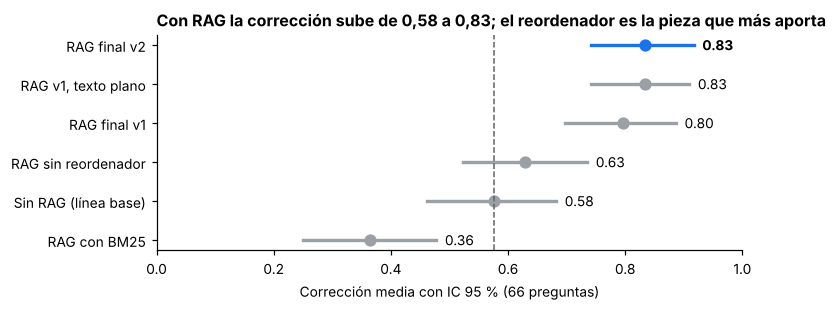

In [5]:
random.seed(2026)
def ic(v, B=10_000):
    m = sorted(sum(random.choices(v, k=len(v))) / len(v) for _ in range(B)); return m[250], m[9749]
def signos(a, b):
    n, k = a + b, min(a, b); return min(1, 2 * sum(math.comb(n, i) for i in range(k + 1)) / 2 ** n)
corr = det.assign(c=num(det["correccion"])).pivot(index="id", columns="config", values="c")
filas = []
for a, b in [("rag_final_v2", "sin_rag"), ("rag_final_v1", "rag_sin_rerank"), ("rag_final_v2", "rag_final_v1")]:
    d = (corr[a] - corr[b]).dropna(); lo, hi = ic(list(d))
    filas.append({"comparación": f"{NOM[a]} vs {NOM[b]}", "diferencia": round(d.mean(), 2),
                  "IC 95 %": f"[{lo:.2f}; {hi:.2f}]", "gana / pierde": f"{(d > 0).sum()} / {(d < 0).sum()}",
                  "p (signos)": round(signos((d > 0).sum(), (d < 0).sum()), 3)})
display(pd.DataFrame(filas))

orden = ["rag_bm25", "sin_rag", "rag_sin_rerank", "rag_final_v1", "rag_final_simple", "rag_final_v2"]
fig, ax = plt.subplots(figsize=(7, 2.9))
for y, c in enumerate(orden):
    lo, hi = ic(list(corr[c])); m = corr[c].mean(); col = ACENTO if c == "rag_final_v2" else GRIS
    ax.plot([lo, hi], [y, y], color=col, lw=2.2); ax.plot(m, y, "o", color=col, ms=7)
    ax.text(hi + 0.015, y, f"{m:.2f}", va="center", fontweight="bold" if col == ACENTO else None)
ax.axvline(corr["sin_rag"].mean(), ls="--", lw=1, color="#5f6368")
ax.set_yticks(range(len(orden))); ax.set_yticklabels([NOM[c] for c in orden]); ax.set_xlim(0, 1)
ax.set_xlabel("Corrección media con IC 95 % (66 preguntas)")
ax.set_title("Con RAG la corrección sube de 0,58 a 0,83; el reordenador es la pieza que más aporta", loc="left")
plt.tight_layout(); plt.show()

**Resultados cualitativos:** dos preguntas, con la respuesta sin RAG y con el RAG final.

In [6]:
for pid in ["nr04", "sen12"]:
    f = det[det["id"] == pid]
    print("■", f["pregunta"].iloc[0], "| referencia:", p.set_index("id").loc[pid, "respuesta_referencia"])
    for c in ["sin_rag", "rag_final_v2"]:
        t = str(f[f["config"] == c]["respuesta"].iloc[0]).replace("\n", " ")
        print(f"   {NOM[c]}: {t[:220]}{'…' if len(t) > 220 else ''}")
    print()

■ ¿Cuál es el torque del servo MG995? | referencia: No está en el corpus: el MG996R solo menciona al MG995 como su predecesor.
   Sin RAG (línea base): El torque del servo MG995 es: * **4.8V:** 9.4 kg-cm * **6.0V:** 11 kg-cm
   RAG final v2: No encuentro esa información en la documentación disponible.

■ ¿Qué fuerza electromotriz genera un termopar tipo K a 125 °C? | referencia: 5124 µV (fila 120 °C, columna 5).
   Sin RAG (línea base): Un termopar tipo K genera aproximadamente 5.08 mV a 125 °C.
   RAG final v2: Un termopar tipo K a 125 °C genera una fuerza electromotriz de 5124 µV [termocuplas_ref, pág. 22].



## E5 · Interpretación, errores, limitaciones y conclusiones

**Interpretación crítica:**
1. **RAG cumple la necesidad.** La corrección sube de 0,58 a 0,83 (p = 0,003) y la
   alucinación baja del 21 % al 2 %. Sin RAG, el modelo respondió con seguridad las 6
   preguntas sin respuesta; con RAG se abstuvo en las 6.
2. **El orden de los resultados importa más que la búsqueda inicial.** El documento
   correcto se encuentra el 95 % de las veces, pero la página correcta queda de primera solo
   el 27 % sin reordenar y el 58 % con el reordenador, que aporta +0,17 en las respuestas
   (p = 0,007).
3. **Un mal buscador anula todo el sistema.** Con BM25 el RAG queda por debajo de no usar
   RAG (0,36), porque se abstiene en el 69 % de las preguntas que sí tienen respuesta.
4. **Medir solo el buscador engaña.** La mejora D22 bajó hit@5 (0,82 → 0,77) pero subió las
   respuestas en preguntas de tabla (0,57 → 0,73).

In [7]:
mal = det[(det["config"] == "rag_final_v2") & (num(det["correccion"]) < 1)]
print(f"Respuestas imperfectas del sistema final: {len(mal)} de 66 · por tipo: {mal['tipo'].value_counts().to_dict()}")
cambio = (corr["rag_final_v2"] - corr["rag_final_v1"])
print("Efecto de D22 por pregunta:", cambio[cambio != 0].to_dict())

Respuestas imperfectas del sistema final: 13 de 66 · por tipo: {'tabla': 5, 'dato': 4, 'multi_doc': 2, 'contradiccion': 1, 'multidispositivo': 1}
Efecto de D22 por pregunta: {'sen08': -0.5, 'sen11': 1.0, 'sen12': 1.0, 'sen13': 1.0}


**Análisis de errores** (15 respuestas imperfectas en v1):

| Origen | n | Mecanismo |
|---|---|---|
| El buscador no trajo la página | 8 | Tablas muy parecidas dentro de un mismo documento; preguntas que cruzan documentos |
| La tabla perdió su contexto al partirse | 3 | **Corregido con D22**: las 3 de termocuplas pasaron a ser correctas |
| El modelo no usó bien el contexto | 4 | Abstención con el dato presente, una contradicción no señalada, celdas combinadas vacías |

**Validez de la evaluación:**
- El juez premiaba las abstenciones; se corrigió calificándolas por regla (BM25 bajó de 0,65 a 0,36).
- Una auditoría manual de 24 respuestas coincidió con el juez en el 92 %; los 2 desacuerdos
  fueron indulgencias de +0,5.

**Limitaciones:**
- Tablas muy parecidas dentro de un mismo documento.
- Preguntas multidocumento: 0,50 frente a 0,62 sin RAG, con n = 4.
- Latencia de 15 s a 1 min por respuesta.
- Un set de 66 preguntas escrito por el mismo equipo.

**Conclusiones y mejoras respaldadas por las pruebas:**
- **Adoptado:** reordenador (+0,17; p = 0,007) y contexto de tablas (preguntas de tabla
  0,57 → 0,73).
- **Descartado:**
  - BM25 y la búsqueda híbrida, porque son peores en todas las configuraciones;
  - el reordenador grande, por costo (78 s por pregunta);
  - los fragmentos de 300 y 600 palabras, por truncamiento y peor hit@5.
- **Próximas mejoras:**
  - filtrar por sección del datasheet para las tablas parecidas;
  - garantizar fragmentos de varios documentos en las preguntas comparativas;
  - escribir preguntas de evaluación para cada documento nuevo;
  - usar modelos ONNX para bajar la latencia.

### Evidencia sustentada personalmente por el estudiante

> **[REVISAR Y AJUSTAR]**
> - Selección del dominio y del corpus: PDF de componentes usados en la carrera.
> - Decisión del alcance y elección del modelo generador, por las restricciones de cómputo y cuota.
> - Configuración de la API, de los repositorios y del despliegue en Streamlit.
> - Sustentación de la arquitectura, de los experimentos y de los resultados de este notebook.
>
> El código se desarrolló con asistencia de IA (Claude); las decisiones están registradas
> en `DECISIONES.md`.